In [16]:
!pip install --upgrade -q yfinance PyPortfolioOpt

In [17]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import yfinance as yf
import concurrent.futures
import matplotlib.pyplot as plt
from datetime import date, timedelta
from pypfopt import EfficientFrontier, expected_returns, objective_functions
from pypfopt.risk_models import CovarianceShrinkage

def download_data(basket, start_date, end_date, interval="1d"):
    data = {}
    for ticker in basket:
        df_ticker = yf.download(ticker, start=start_date, end=end_date, auto_adjust=False, interval=interval)['Close']
        data[ticker] = df_ticker
    df = pd.concat(data, axis=1).ffill().fillna(0)
    if df.isnull().values.any():
        raise ValueError("Data contains NaN values even after filling!")
    return df

In [21]:
basket = ["EURUSD=X", "GC=F", "BTC-USD"]
# basket = ["USDC-USD", "PAXG-USD", "BTC-USD", "ETH-USD", "SOL-USD", "FDUSD-USD", "XRP-USD", "DOGE-USD", "BNB-USD", "ADA-USD",
#           "LINK-USD", "AVAX-USD", "SUI20947-USD", "TRX-USD", "WLD-USD", "BCH-USD", "LTC-USD", "ENA-USD",
#           "PEPE24478-USD", "AAVE-USD", "BONK-USD", "ARB11841-USD", "ONDO-USD",
#           "XLM-USD",  "HBAR-USD", "DOT-USD", "SHIB-USD", "SEI-USD", "USDE29470-USD",
#           "TON11419-USD", "OP-USD", "WIF-USD", "NEAR-USD", "POL28321-USD", "FIL-USD",
#           "TAO22974-USD", "PENDLE-USD", "ETC-USD", "INJ-USD", "ENS-USD", "CFX-USD", "LDO-USD", "VIRTUAL-USD",
#           "ATOM-USD", "GALA-USD", "FET-USD", "FLOKI-USD",
#           "RAY-USD", "ALGO-USD", "ICP-USD", "RENDER-USD", "CAKE-USD", "SAND-USD",
#           "IMX10603-USD", "VET-USD", "XTZ-USD",
#           "IOTA-USD", "THETA-USD", "QNT-USD", "NEXO-USD"]

end_date = date.today() - timedelta(days=1)
# end_date = date.fromisoformat("2025-08-19")
start_date = end_date - timedelta(days=3648)
# end_date = end_date.strftime("%Y-%m-%d")
df = download_data(basket, start_date, end_date)


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [22]:
pd.set_option('display.max_columns', None)

df

,EURUSD=X,GC=F,BTC-USD
Ticker,EURUSD=X,GC=F,BTC-USD
Date,,,
2016-02-08,1.114504,1197.900024,373.446991
2016-02-09,1.118981,1198.699951,376.028992
2016-02-10,1.128999,1194.699951,381.648987
2016-02-11,1.128095,1247.900024,379.653992
2016-02-12,1.131798,1239.099976,384.263000
...,...,...,...
2026-01-29,1.197777,5318.399902,84561.585938
2026-01-30,1.196573,4713.899902,84128.656250


['BTC-USD', 'GC=F', 'EURUSD=X']
Portfolio Comparison:
       Portfolio Type  Return Volatility  Sharpe Ratio
0         Max Sharpe  16.21%     15.45%      1.049088
1     Min Volatility   2.90%      6.02%      0.482143
2  Optimal Portfolio  20.00%     19.49%      1.026128

Sharpe Portfolio:
Weights:
       Token Allocation
0       BTC     19.98%
1      GOLD     74.04%
2  EURUSD=X      5.97%
Performance: Return = 16.21%, Volatility = 15.45%, Sharpe Ratio = 1.05


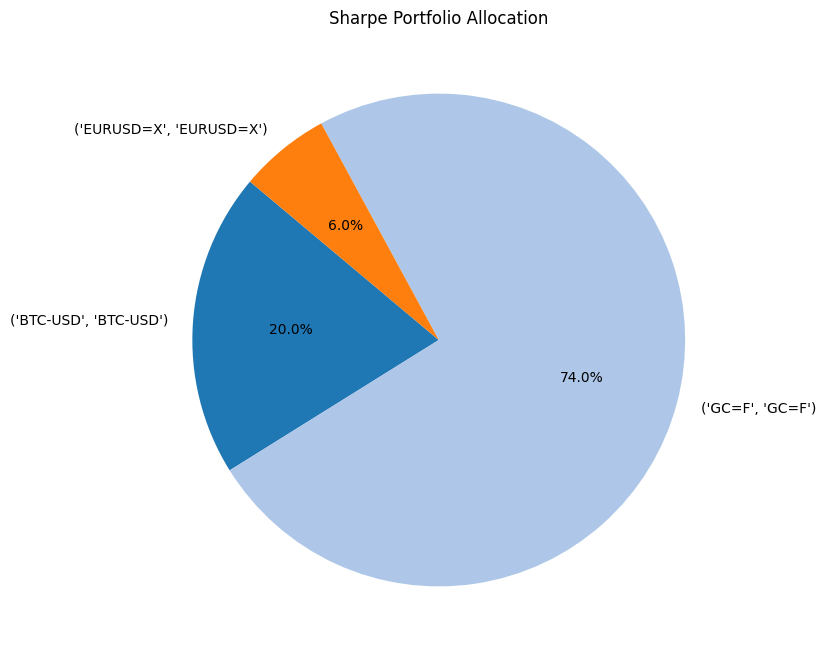


Volatility Portfolio:
Weights:
       Token Allocation
0       BTC      2.00%
1      GOLD     16.99%
2  EURUSD=X     81.01%
Performance: Return = 2.90%, Volatility = 6.02%, Sharpe Ratio = 0.48


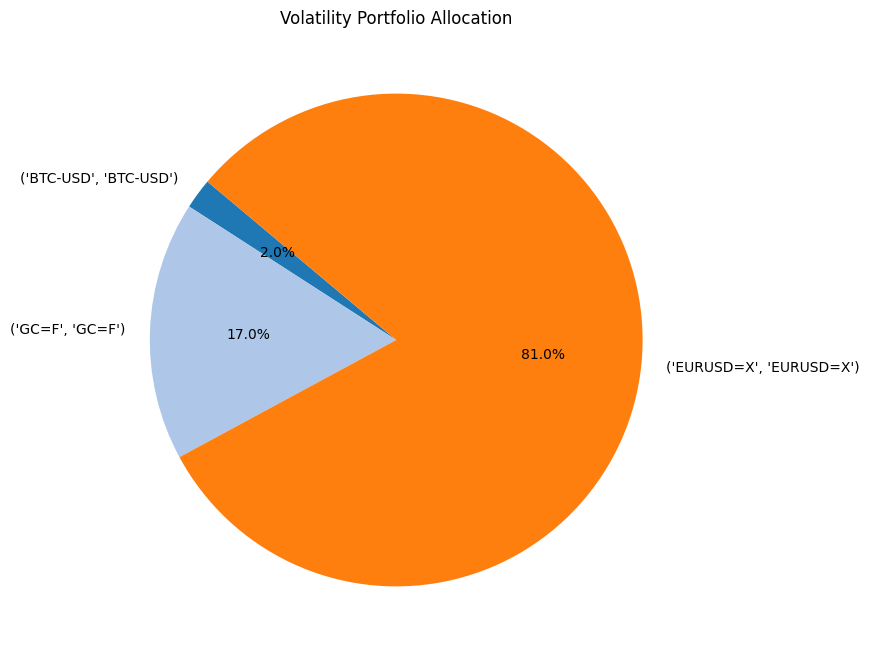


Optimal Portfolio:
Weights:
       Token Allocation
0       BTC     29.78%
1      GOLD     68.22%
2  EURUSD=X      2.00%
Performance: Return = 20.00%, Volatility = 19.49%, Sharpe Ratio = 1.03


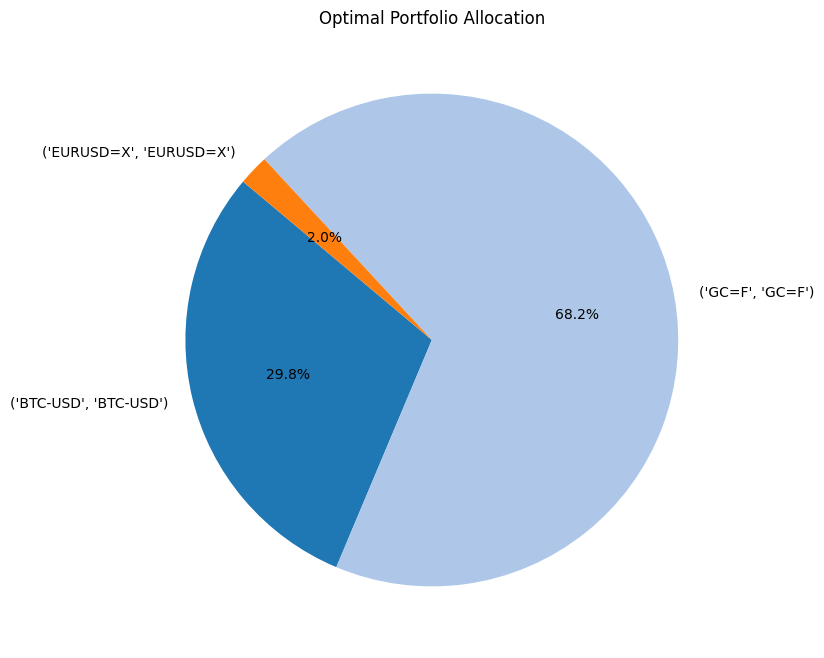

In [23]:
def calculate_max_drawdown(returns_series: pd.Series) -> float:
    """Tính toán Maximum Drawdown từ một chuỗi lợi nhuận."""
    equity_curve = (1 + returns_series).cumprod()
    peak = equity_curve.expanding(min_periods=1).max()
    drawdown = (equity_curve - peak) / peak
    return drawdown.min()

def filter_top_assets(df, max_assets, criterion="sharpe", required_assets=None):
    # Tính lợi suất kỳ vọng
    mu = expected_returns.mean_historical_return(df)
    # Tính độ lệch chuẩn từ lợi suất hàng ngày
    daily_returns = df.pct_change().dropna()
    if daily_returns.isna().any().any():
        raise ValueError("The data after calculation contains NaN. Please check the input data.")

    std_devs = daily_returns.std()

    if criterion == "sharpe":
        sharpe_ratios = mu / std_devs  # Tính Sharpe Ratio
        if isinstance(sharpe_ratios.index, pd.MultiIndex):
            sharpe_ratios.index = sharpe_ratios.index.map(lambda x: x[0])
        top_assets = sharpe_ratios.nlargest(max_assets).index.tolist()  # Lấy top tài sản theo Sharpe Ratio
    elif criterion == "volatility":
        std_devs.index = std_devs.index.map(lambda x: x[0])
        top_assets = std_devs.nsmallest(max_assets).index.tolist()  # Lấy top tài sản có độ biến động thấp nhất
    else:
        raise ValueError("Criterion not supported! Use 'sharpe' or 'volatility'.")

    # Đảm bảo các tài sản bắt buộc luôn có mặt
    if required_assets is not None:
        # Loại bỏ các tài sản trong required_assets khỏi top_assets
        top_assets = [asset for asset in top_assets if asset not in required_assets]
        # Thêm các tài sản bắt buộc vào đầu danh sách
        top_assets = required_assets + top_assets
        # Giữ đúng số lượng tài sản tối đa
        top_assets = top_assets[:max_assets]

    print(top_assets)  # In danh sách ticker
    return df[top_assets]

def optimize_portfolio(df_filtered, target_return=0.2, min_weight=0.05, usd_max_weight=0.33):
    mu = expected_returns.mean_historical_return(df_filtered)
    S = CovarianceShrinkage(df_filtered).ledoit_wolf()

    ef_sharpe = EfficientFrontier(mu, S)
    ef_volatility = EfficientFrontier(mu, S)
    ef_optimal = EfficientFrontier(mu, S)

    # Áp dụng ràng buộc trọng số tối thiểu
    for ef in [ef_sharpe, ef_volatility, ef_optimal]:
        ef.add_constraint(lambda w: w >= min_weight)

        # Kiểm tra nếu USDT-USD có trong danh sách tài sản
        if "USDC-USD" in df_filtered.columns:
            ef.add_constraint(lambda w, ticker="USDC-USD": w[df_filtered.columns.get_loc(ticker)] <= usd_max_weight)
        if "USDT-USD" in df_filtered.columns:
            ef.add_constraint(lambda w, ticker="USDT-USD": w[df_filtered.columns.get_loc(ticker)] <= usd_max_weight)

    # 1. Portfolio có tỷ lệ Sharpe cao nhất
    ef_sharpe.max_sharpe()
    weights_sharpe = ef_sharpe.clean_weights()
    performance_sharpe = ef_sharpe.portfolio_performance(verbose=False)

    # 2. Portfolio có độ biến động thấp nhất
    ef_volatility.min_volatility()
    weights_volatility = ef_volatility.clean_weights()
    performance_volatility = ef_volatility.portfolio_performance(verbose=False)

    # 3. Portfolio tối ưu (giữa rủi ro và lợi suất)
    ef_optimal.efficient_return(target_return=target_return)
    weights_optimal = ef_optimal.clean_weights()
    performance_optimal = ef_optimal.portfolio_performance(verbose=False)

    return {
        "sharpe": (weights_sharpe, performance_sharpe),
        "volatility": (weights_volatility, performance_volatility),
        "optimal": (weights_optimal, performance_optimal),
    }

def plot_portfolio(weights, title):
    filtered_weights = {key: weight for key, weight in weights.items() if weight > 0}
    assets = list(filtered_weights.keys())
    weights = list(filtered_weights.values())

    plt.figure(figsize=(8, 8))
    plt.pie(weights, labels=assets, autopct='%1.1f%%', startangle=140, colors=plt.cm.tab20.colors)
    plt.title(title)
    plt.show()

def plot_equity_curves(df_filtered, results):
    # Compute daily returns
    daily_returns = df_filtered.pct_change().fillna(0)

    # Create a Plotly figure
    fig = go.Figure()

    # Loop over each portfolio type in results
    for portfolio_type, (weights_ordered, metrics) in results.items():
        # Extract tickers and weights
        tickers = [key[0] for key in weights_ordered.keys()]
        weights = np.array(list(weights_ordered.values()))

        # Compute portfolio returns
        port_returns = daily_returns[tickers].dot(weights)

        # Compute equity curve starting from 1
        equity = (1 + port_returns).cumprod()
        equity = pd.concat([pd.Series([1.0], index=[df_filtered.index[0]]), equity])

        # Add trace to the figure
        fig.add_trace(go.Scatter(x=equity.index, y=equity.values, mode='lines', name=f'{portfolio_type.capitalize()} Portfolio'))

        mdd = calculate_max_drawdown(port_returns)
        print(f"{portfolio_type.capitalize()} Portfolio - Max Drawdown: {mdd:.2%}")

    # Update layout
    fig.update_layout(
        title='Equity Curves for Portfolios',
        xaxis_title='Date',
        yaxis_title='Equity',
        legend_title='Portfolio Type'
    )

    # Show the figure
    fig.show()

def main(df, max_assets, min_weight, target_return, criterion, required_assets=None, usd_max_weight=None):

    # Filter top assets
    df = filter_top_assets(df, max_assets, criterion, required_assets)

    # Optimize portfolio
    results = optimize_portfolio(df, target_return, min_weight, usd_max_weight)

    # Create Portfolio Comparison DataFrame
    portfolio_data = {
        "Portfolio Type": ["Max Sharpe", "Min Volatility", "Optimal Portfolio"],
        "Return": [
            results["sharpe"][1][0],
            results["volatility"][1][0],
            results["optimal"][1][0],
        ],
        "Volatility": [
            results["sharpe"][1][1],
            results["volatility"][1][1],
            results["optimal"][1][1],
        ],
        "Sharpe Ratio": [
            results["sharpe"][1][2],
            results["volatility"][1][2],
            results["optimal"][1][2],
        ],
    }
    portfolio_df = pd.DataFrame(portfolio_data)

    for column in ["Return", "Volatility"]:
        portfolio_df[column] = portfolio_df[column].apply(lambda x: f"{x * 100:.2f}%")

    print("Portfolio Comparison:\n", portfolio_df)

    # Display results for each portfolio type
    for portfolio_type, (weights, performance) in results.items():
        weight = pd.DataFrame([
          {'Token': 'GOLD' if k[0] == 'GC=F' else k[0].replace('-USD', ''), 'Allocation': f"{v*100:.2f}%"}
          for k, v in weights.items()
        ])

        print(f"\n{portfolio_type.capitalize()} Portfolio:")
        print("Weights:\n", weight)
        print("Performance: Return = {:.2f}%, Volatility = {:.2f}%, Sharpe Ratio = {:.2f}".format(
            performance[0] * 100, performance[1] * 100, performance[2]
        ))
        plot_portfolio(weights, f"{portfolio_type.capitalize()} Portfolio Allocation")

    return df, results

max_assets = 5
min_weight = 0.02
target_return = 0.2
usd_max_weight = 0.34
criterion = "sharpe"  # "sharpe" or "volatility"

required_assets = ['BTC-USD', 'GC=F']

df_filtered, results = main(df, max_assets, min_weight, target_return, criterion, required_assets, usd_max_weight)

In [ ]:
plot_equity_curves(df_filtered, results)

In [ ]:
from pypfopt import risk_models
import seaborn as sns
import matplotlib.pyplot as plt

def calculate_correlation_matrix(df):
    cov_matrix = CovarianceShrinkage(df).ledoit_wolf()
    correlation_matrix = cov_matrix.corr()
    return cov_matrix, correlation_matrix

def plot_correlation_matrix(correlation_matrix):
    plt.figure(figsize=(18, 10))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True,
                linewidths=0.5, linecolor='black')
    plt.title("Asset Correlation Matrix (PyPortfolioOpt)", fontsize=16)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

mu = expected_returns.mean_historical_return(df)
S, correlation_matrix = calculate_correlation_matrix(df)

# print(correlation_matrix)

# plot_correlation_matrix(correlation_matrix)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pypfopt import expected_returns
from pypfopt.risk_models import CovarianceShrinkage

# Hàm tính hiệu suất của portfolio theo trọng số đã cho
def portfolio_performance(weights, mu, S):
    weights = np.array(weights)
    returns = np.dot(weights, mu)
    volatility = np.sqrt(np.dot(weights.T, np.dot(S, weights)))
    return returns, volatility

# Hàm xây dựng Efficient Frontier
def efficient_frontier(mu, S, num_points=100):
    results = np.zeros((3, num_points))
    for i in range(num_points):
        weights = np.random.random(len(mu))
        weights /= np.sum(weights)
        port_return, port_volatility = portfolio_performance(weights, mu, S)
        results[0, i] = port_return
        results[1, i] = port_volatility
        results[2, i] = port_return / port_volatility  # Tỷ lệ Sharpe
    return results

# Hàm vẽ Efficient Frontier kèm các điểm portfolio tối ưu
def plot_efficient_frontier(results, mu, S, weights_optimal, weights_sharpe):
    plt.figure(figsize=(10, 6))
    sc = plt.scatter(results[1, :], results[0, :], c=results[2, :], cmap='viridis', marker='o')
    plt.title('Efficient Frontier (Filtered Assets)')
    plt.xlabel('Volatility')
    plt.ylabel('Return')
    plt.colorbar(sc, label='Sharpe Ratio')

    optimal_return, optimal_volatility = portfolio_performance(list(weights_optimal.values()), mu, S)
    max_sharpe_return, max_sharpe_volatility = portfolio_performance(list(weights_sharpe.values()), mu, S)

    plt.scatter(optimal_volatility, optimal_return, color='red', marker='*', s=200, label='Optimal Portfolio')
    plt.scatter(max_sharpe_volatility, max_sharpe_return, color='green', marker='*', s=200, label='Max Sharpe Portfolio')
    plt.legend()
    plt.show()

# Tính lại vector lợi suất kỳ vọng và ma trận hiệp phương sai dựa trên dữ liệu đã lọc (df_filtered từ cell 1)
mu_filtered = expected_returns.mean_historical_return(df_filtered)
S_filtered = CovarianceShrinkage(df_filtered).ledoit_wolf()

# Tính Efficient Frontier cho danh mục đã lọc
frontier_results = efficient_frontier(mu_filtered, S_filtered)

# Lấy trọng số portfolio tối ưu và portfolio có Sharpe cao nhất từ kết quả tối ưu hóa trả về từ main
weights_optimal = results["optimal"][0]
weights_sharpe = results["sharpe"][0]

# Vẽ đường Efficient Frontier
# plot_efficient_frontier(frontier_results, mu_filtered, S_filtered, weights_optimal, weights_sharpe)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pypfopt import expected_returns, CovarianceShrinkage, EfficientFrontier, DiscreteAllocation, get_latest_prices

class AssetFilter:
    def __init__(self, df, max_assets, criterion="sharpe", required_assets=None):
        self.df = df
        self.max_assets = max_assets
        self.criterion = criterion
        self.required_assets = required_assets

    def filter_top_assets(self):
        mu = expected_returns.mean_historical_return(self.df)
        daily_returns = self.df.pct_change().dropna()
        if daily_returns.isna().any().any():
            raise ValueError("The data after calculation contains NaN. Please check the input data.")
        std_devs = daily_returns.std()

        if self.criterion == "sharpe":
            sharpe_ratios = mu / std_devs
            if isinstance(sharpe_ratios.index, pd.MultiIndex):
                sharpe_ratios.index = sharpe_ratios.index.map(lambda x: x[0])
            top_assets = sharpe_ratios.nlargest(self.max_assets).index.tolist()
        elif self.criterion == "volatility":
            std_devs.index = std_devs.index.map(lambda x: x[0])
            top_assets = std_devs.nsmallest(self.max_assets).index.tolist()
        else:
            raise ValueError("Criterion not supported! Use 'sharpe' or 'volatility'.")

        if self.required_assets is not None:
            top_assets = [asset for asset in top_assets if asset not in self.required_assets]
            top_assets = self.required_assets + top_assets
            top_assets = top_assets[:self.max_assets]

        print("Filtered assets:", top_assets)
        return self.df[top_assets]

class PortfolioOptimizer:
    def __init__(self, df_filtered, target_return=0.2, min_weight=0.05, usd_max_weight=0.33):
        self.df_filtered = df_filtered
        self.target_return = target_return
        self.min_weight = min_weight
        self.usd_max_weight = usd_max_weight
        self.mu = expected_returns.mean_historical_return(df_filtered)
        self.S = CovarianceShrinkage(df_filtered).ledoit_wolf()

    def optimize_portfolio(self):
        ef_sharpe = EfficientFrontier(self.mu, self.S)
        ef_volatility = EfficientFrontier(self.mu, self.S)
        ef_optimal = EfficientFrontier(self.mu, self.S)

        for ef in [ef_sharpe, ef_volatility, ef_optimal]:
            ef.add_constraint(lambda w: w >= self.min_weight)
            if "USDC-USD" in self.df_filtered.columns:
                ef.add_constraint(lambda w: w[self.df_filtered.columns.get_loc("USDC-USD")] <= self.usd_max_weight)
            if "USDT-USD" in self.df_filtered.columns:
                ef.add_constraint(lambda w: w[self.df_filtered.columns.get_loc("USDT-USD")] <= self.usd_max_weight)

        ef_sharpe.max_sharpe()
        weights_sharpe = ef_sharpe.clean_weights()
        performance_sharpe = ef_sharpe.portfolio_performance(verbose=False)

        ef_volatility.min_volatility()
        weights_volatility = ef_volatility.clean_weights()
        performance_volatility = ef_volatility.portfolio_performance(verbose=False)

        ef_optimal.efficient_return(target_return=self.target_return)
        weights_optimal = ef_optimal.clean_weights()
        performance_optimal = ef_optimal.portfolio_performance(verbose=False)

        return {
            "sharpe": (weights_sharpe, performance_sharpe),
            "volatility": (weights_volatility, performance_volatility),
            "optimal": (weights_optimal, performance_optimal),
        }

class PortfolioVisualizer:
    @staticmethod
    def plot_portfolio(weights, title):
        filtered_weights = {k: v for k, v in weights.items() if v > 0}
        assets = list(filtered_weights.keys())
        weights = list(filtered_weights.values())
        plt.figure(figsize=(8, 8))
        plt.pie(weights, labels=assets, autopct='%1.1f%%', startangle=140, colors=plt.cm.tab20.colors)
        plt.title(title)
        plt.savefig(f"{title.lower().replace(' ', '_')}.png")

    @staticmethod
    def plot_correlation_matrix(correlation_matrix):
        plt.figure(figsize=(18, 10))
        sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True,
                    linewidths=0.5, linecolor='black')
        plt.title("Asset Correlation Matrix", fontsize=16)
        plt.xticks(rotation=45, ha="right")
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.savefig('correlation_matrix.png')

    @staticmethod
    def portfolio_performance(weights, mu, S):
        weights = np.array(list(weights.values()))
        returns = np.dot(weights, mu)
        volatility = np.sqrt(np.dot(weights.T, np.dot(S, weights)))
        return returns, volatility

    def plot_efficient_frontier(self, mu, S, weights_optimal, weights_sharpe):
        results = np.zeros((3, 100))
        for i in range(100):
            weights = np.random.random(len(mu))
            weights /= np.sum(weights)
            port_return, port_volatility = self.portfolio_performance(dict(zip(mu.index, weights)), mu, S)
            results[0, i] = port_return
            results[1, i] = port_volatility
            results[2, i] = port_return / port_volatility

        plt.figure(figsize=(10, 6))
        sc = plt.scatter(results[1, :], results[0, :], c=results[2, :], cmap='viridis', marker='o')
        plt.title('Efficient Frontier (Filtered Assets)')
        plt.xlabel('Volatility')
        plt.ylabel('Return')
        plt.colorbar(sc, label='Sharpe Ratio')

        optimal_return, optimal_volatility = self.portfolio_performance(weights_optimal, mu, S)
        sharpe_return, sharpe_volatility = self.portfolio_performance(weights_sharpe, mu, S)

        plt.scatter(optimal_volatility, optimal_return, color='red', marker='*', s=200, label='Optimal Portfolio')
        plt.scatter(sharpe_volatility, sharpe_return, color='green', marker='*', s=200, label='Max Sharpe Portfolio')
        plt.legend()
        plt.savefig('efficient_frontier.png')

class DiscreteAllocator:
    def __init__(self, df_filtered, total_portfolio_value, min_allocation_requirements):
        self.df_filtered = df_filtered
        self.total_portfolio_value = total_portfolio_value
        self.min_allocation_requirements = min_allocation_requirements
        self.latest_prices = get_latest_prices(df_filtered)

    def get_price(self, asset_name):
        price = self.latest_prices[asset_name]
        if hasattr(price, 'iloc'):
            price = price.iloc[0]
        return float(price)

    def adjust_allocation(self, allocation, leftover):
        adjusted = True
        while adjusted:
            adjusted = False
            for asset_tuple in list(allocation.keys()):
                asset_name = asset_tuple[0]
                current_shares = allocation[asset_tuple]
                share_price = self.get_price(asset_name)
                req_value, _ = self.min_allocation_requirements.get(asset_name, (10, "dollars"))
                if (current_shares * share_price) < req_value:
                    if leftover >= share_price:
                        allocation[asset_tuple] += 1
                        leftover -= share_price
                        adjusted = True
                    else:
                        print(f"Warning: Not enough funds for {asset_name} (requires ${req_value}).")
        return allocation, leftover

    def allocate(self, weights):
        da = DiscreteAllocation(weights, self.latest_prices, total_portfolio_value=self.total_portfolio_value)
        allocation, leftover = da.greedy_portfolio()
        allocation, leftover = self.adjust_allocation(allocation, leftover)
        allocated_value = sum(float(shares) * self.get_price(asset_tuple[0]) for asset_tuple, shares in allocation.items())
        return allocation, leftover, allocated_value

def main(df, max_assets, min_weight, target_return, criterion, required_assets=None, usd_max_weight=0.34, min_allocation_requirements=None):
    # Filter assets
    asset_filter = AssetFilter(df, max_assets, criterion, required_assets)
    df_filtered = asset_filter.filter_top_assets()

    # Optimize portfolio
    optimizer = PortfolioOptimizer(df_filtered, target_return, min_weight, usd_max_weight)
    results = optimizer.optimize_portfolio()

    return df_filtered, results

def format_portfolio_metrics(data):
    """
    Format kết quả portfolio optimization thành bảng Pandas:
    - Weights, return, volatility dạng %
    - Sharpe giữ nguyên
    """
    assets = list(next(iter(data.values()))[0].keys())
    assets = [a[0] for a in assets]

    rows = []
    for strategy, (weights_dict, metrics) in data.items():
        row = {'strategy': strategy}
        for asset, weight in weights_dict.items():
            row[asset[0]] = weight * 100  # chuyển sang %
        row['return'] = metrics[0] * 100
        row['volatility'] = metrics[1] * 100
        row['sharpe'] = metrics[2]
        rows.append(row)

    df = pd.DataFrame(rows)
    df.set_index("strategy", inplace=True)

    percent_cols = [col for col in df.columns if col != 'sharpe']
    df[percent_cols] = df[percent_cols].round(2)
    df['sharpe'] = df['sharpe'].round(4)

    return df

# Example usage
if __name__ == "__main__":

  basket = ["USDC-USD", "PAXG-USD", "BTC-USD", "ETH-USD", "SOL-USD", "XRP-USD", "DOGE-USD", "BNB-USD", "ADA-USD",
          "LINK-USD", "TRX-USD", "BCH-USD", "LTC-USD"]
          # "PEPE24478-USD", "AAVE-USD", "BONK-USD", "ARB11841-USD", "ONDO-USD",
          # "XLM-USD",  "HBAR-USD", "DOT-USD", "SHIB-USD", "SEI-USD", "USDE29470-USD",
          # "TON11419-USD", "OP-USD", "WIF-USD", "NEAR-USD", "POL28321-USD", "FIL-USD",
          # "TAO22974-USD", "PENDLE-USD", "ETC-USD", "INJ-USD", "ENS-USD", "CFX-USD", "LDO-USD", "VIRTUAL-USD",
          # "ATOM-USD", "GALA-USD", "FET-USD", "FLOKI-USD",
          # "RAY-USD", "ALGO-USD", "ICP-USD", "RENDER-USD", "CAKE-USD", "SAND-USD",
          # "IMX10603-USD", "VET-USD", "XTZ-USD",
          # "IOTA-USD", "THETA-USD", "QNT-USD", "NEXO-USD"]

  end_date = date.today() - timedelta(days=1)
  # end_date = date.fromisoformat("2025-08-12")
  start_date = end_date - timedelta(days=1500)
  end_date = end_date.strftime("%Y-%m-%d")
  df = download_data(basket, start_date, end_date, "1d")

  print(f"Data count: {len(df)}")
  max_assets = 3
  min_weight = 0.04
  target_return = 0.17
  usd_max_weight = 0.34
  criterion = "sharpe"
  required_assets = ['BTC-USD', 'PAXG-USD']
  min_allocation_requirements = {
      'BTC-USD': (2, "dollars"),
      'ONUS-USD': (2, "dollars"),
      'USDC-USD': (10, "dollars"),
      'PAXG-USD': (10, "dollars")
  }

  df_filtered, results = main(df, max_assets, min_weight, target_return, criterion, required_assets, usd_max_weight, min_allocation_requirements)

  print(format_portfolio_metrics(results))
  plot_equity_curves(df_filtered, results)

In [ ]:
if __name__ == "__main__":

  basket = ["USDC-USD", "PAXG-USD", "BTC-USD", "ETH-USD", "SOL-USD", "XRP-USD", "DOGE-USD", "BNB-USD", "ADA-USD",
          "LINK-USD", "TRX-USD", "BCH-USD", "LTC-USD"]
          # "PEPE24478-USD", "AAVE-USD", "BONK-USD", "ARB11841-USD", "ONDO-USD",
          # "XLM-USD",  "HBAR-USD", "DOT-USD", "SHIB-USD", "SEI-USD", "USDE29470-USD",
          # "TON11419-USD", "OP-USD", "WIF-USD", "NEAR-USD", "POL28321-USD", "FIL-USD",
          # "TAO22974-USD", "PENDLE-USD", "ETC-USD", "INJ-USD", "ENS-USD", "CFX-USD", "LDO-USD", "VIRTUAL-USD",
          # "ATOM-USD", "GALA-USD", "FET-USD", "FLOKI-USD",
          # "RAY-USD", "ALGO-USD", "ICP-USD", "RENDER-USD", "CAKE-USD", "SAND-USD",
          # "IMX10603-USD", "VET-USD", "XTZ-USD",
          # "IOTA-USD", "THETA-USD", "QNT-USD", "NEXO-USD"]

  end_date = date.today() - timedelta(days=1)
  start_date = end_date - timedelta(days=365)
  end_date = end_date.strftime("%Y-%m-%d")

  df = download_data(basket, start_date, end_date, "1d")

  max_assets = 3
  min_weight = 0.05
  target_return = 0.34
  usd_max_weight = 0.34
  criterion = "sharpe"
  required_assets = ['BTC-USD', 'PAXG-USD']
  min_allocation_requirements = {
      'BTC-USD': (2, "dollars"),
      'ONUS-USD': (2, "dollars"),
      'USDC-USD': (10, "dollars"),
      'PAXG-USD': (10, "dollars")
  }

  df_filtered, results = main(df, max_assets, min_weight, target_return, criterion, required_assets, usd_max_weight, min_allocation_requirements)

  print(format_portfolio_metrics(results))
  plot_equity_curves(df_filtered, results)